# Tối ưu hóa siêu tham số (Hyperparameter Optimization) với Optuna và TensorFlow

---

Notebook này giúp bạn tự động tìm ra bộ tham số tốt nhất cho mô hình.
- `learning_rate`: Tốc độ học
- `scheduler_type`: Chọn giữa `none`, `step`, `cosine`, `exponential`, `reduce`
- `weight_decay`: Trọng số suy giảm của `AdamW`
- `loss_type`: Chọn giữa `BinaryCrossentropy` (ce) hoặc `BinaryFocalCrossentropy` (focal)
- `label_smoothing`: Tham số làm giảm độ tự tin quá mức của mô hình, được sử dụng khi dùng `BinaryCrossEntropy`
- `gamma`: Tham số cho `Focal Loss` nhằm tập trung vào mẫu khó, được sử dụng khi dùng `BinaryFocalCrossentropy`


In [1]:
import os
import sys
import matplotlib.pyplot as plt

import optuna
import optuna.visualization.matplotlib as vis

from optuna.integration import TFKerasPruningCallback
from optuna.pruners import MedianPruner

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' 

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.optimizers import AdamW
from keras.losses import BinaryCrossentropy, BinaryFocalCrossentropy
from keras.optimizers.schedules import CosineDecay, ExponentialDecay
from keras.callbacks import ReduceLROnPlateau
from keras.utils import image_dataset_from_directory, set_random_seed
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomContrast, RandomTranslation, RandomBrightness

sys.path.append(os.path.abspath('..'))
from models.CustomModel import custom_model
from src.evaluate import MetricsCallback

I0000 00:00:1791677339.761768  110412 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791677339.792256  110412 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791677340.872009  110412 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/optuna/integration/tfkeras.py:14: FutureWa

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
TRIAL_EPOCHS = 5
N_TRIALS = 10
SEED = 42

set_random_seed(SEED)
os.makedirs('../cache/optimize', exist_ok=True)

## 1. Chuẩn bị dữ liệu

---

In [2]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.015, fill_mode='nearest'),
    RandomZoom(height_factor=(-0.1, 0.0), width_factor=(-0.1, 0.0)),
    RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    RandomContrast(factor=0.2),
    RandomBrightness(factor=0.1)
])

E0000 00:00:1791677341.628226  110412 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [3]:
train_dir = '../datasets/LCC_FASD/train'
val_dir = '../datasets/LCC_FASD/val'

print("Tập Train:")
train_ds = image_dataset_from_directory(
    train_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE, 
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

print("\nTập Validation:")
val_ds = image_dataset_from_directory(
    val_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE, 
    label_mode='binary',
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = (
    train_ds
    .cache('../cache/optimize/train_cache')
    .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    .prefetch(buffer_size=AUTOTUNE)
)

val_ds = (
    val_ds
    .cache('../cache/optimize/val_cache')
    .prefetch(buffer_size=AUTOTUNE)
)

Tập Train:
Found 8299 files belonging to 2 classes.

Tập Validation:
Found 2948 files belonging to 2 classes.


In [4]:
labels = ["real", "spoof"]
real_counts = 0
spoof_counts = 0

for label in labels:
    label_dir = os.path.join(train_dir, label)
    count = len(os.listdir(label_dir))
    if label == "real":
        real_counts = count
    else:
        spoof_counts = count
    print(f"Số lượng ảnh {label}: {count}")

total_counts = real_counts + spoof_counts
print(f"Tổng số lượng ảnh: {total_counts}")
class_weights = {0: total_counts / (2 * real_counts), 1: total_counts / (2 * spoof_counts)}
print(f"Class weights: {class_weights}")

Số lượng ảnh real: 1223
Số lượng ảnh spoof: 7076
Tổng số lượng ảnh: 8299
Class weights: {0: 3.392886345053148, 1: 0.5864188807235726}


## 2. Định nghĩa hàm Objective cho Optuna

---

In [5]:
def objective(trial):
    keras.backend.clear_session()

    lr = trial.suggest_float("lr", 1e-5, 5e-4, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 5e-2, log=True)
    loss_type = trial.suggest_categorical("loss_type", ["ce", "focal"])
    scheduler_type = trial.suggest_categorical("scheduler_type", ["none", "step", "cosine", "exponential", "reduce"])
    gamma = trial.suggest_float("gamma", 0.5, 3.0)
    label_smoothing=trial.suggest_float("label_smoothing", 0.0, 0.1)

    if loss_type == "ce":
        loss_fn = BinaryCrossentropy(label_smoothing=label_smoothing)
    else:
        loss_fn = BinaryFocalCrossentropy(gamma=gamma)
        
    steps_per_epoch = len(train_ds)
    if scheduler_type == "cosine":
        lr_schedule = CosineDecay(initial_learning_rate=lr, decay_steps=TRIAL_EPOCHS * steps_per_epoch)

    elif scheduler_type == "exponential":
        lr_schedule = ExponentialDecay(initial_learning_rate=lr, decay_steps=steps_per_epoch, decay_rate=0.9, staircase=False)

    elif scheduler_type == "step":
        lr_schedule = ExponentialDecay(initial_learning_rate=lr, decay_steps=steps_per_epoch, decay_rate=0.5, staircase=True)

    else:
        lr_schedule = lr

    metrics_cb = MetricsCallback(val_dataset=val_ds, save_dir='../outputs/optimize', output_name=f"trial_{trial.number}")
    callbacks = [metrics_cb, TFKerasPruningCallback(trial, 'val_loss')]
    if scheduler_type == "reduce":
        callbacks.append(ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)) 

    model = custom_model(input_shape=(IMG_SIZE, IMG_SIZE, 3))
    optimizer = AdamW(learning_rate=lr_schedule, weight_decay=weight_decay, clipnorm=1.0)
    model.compile(optimizer=optimizer, loss=loss_fn, metrics=['accuracy'])

    print(f"-> Bắt đầu Trial {trial.number} lr={lr:.5f}, schedule={scheduler_type}, weight_decay={weight_decay}, loss={loss_type}, label_smoothing={label_smoothing}, gamma={gamma}")
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=TRIAL_EPOCHS,
        callbacks=callbacks,
        class_weight=class_weights,
        shuffle=False,
        verbose=0
    )

    val_acer = metrics_cb.best_acer
    print(f"-> Kết thúc Trial {trial.number}] ACER Tốt nhất đạt: {val_acer*100:.2f}%")
    
    return val_acer


## 3. Chạy quá trình tìm kiếm (Optimize)

---

In [6]:
study = optuna.create_study(direction="minimize", pruner=MedianPruner(n_startup_trials=2, n_warmup_steps=2))

study.enqueue_trial({"lr": 3.63e-4, "scheduler_type": "cosine", "loss_type": "focal", "gamma": 2.0, "weight_decay": 2e-3})

study.optimize(objective, n_trials=N_TRIALS)

[I 2026-10-11 07:09:02,077] A new study created in memory with name: no-name-955a96bd-efe7-4cb1-ba86-0ddb387797d6


-> Bắt đầu Trial 0 lr=0.00036, schedule=cosine, weight_decay=0.002, loss=focal, label_smoothing=0.010430258610861243, gamma=2.0
 - APCER: 26.07% - BPCER: 26.17% - ACER: 26.12% (t*: 0.5723) ⭐ NEW BEST
 - APCER: 26.78% - BPCER: 26.91% - ACER: 26.85% (t*: 0.7083) 
 - APCER: 20.41% - BPCER: 20.49% - ACER: 20.45% (t*: 0.3151) ⭐ NEW BEST
 - APCER: 16.24% - BPCER: 16.30% - ACER: 16.27% (t*: 0.2497) ⭐ NEW BEST


[I 2026-10-11 07:14:45,182] Trial 0 finished with value: 0.15968065325779313 and parameters: {'lr': 0.000363, 'weight_decay': 0.002, 'loss_type': 'focal', 'scheduler_type': 'cosine', 'gamma': 2.0, 'label_smoothing': 0.010430258610861243}. Best is trial 0 with value: 0.15968065325779313.


 - APCER: 15.89% - BPCER: 16.05% - ACER: 15.97% (t*: 0.2713) ⭐ NEW BEST
-> Kết thúc Trial 0] ACER Tốt nhất đạt: 15.97%
-> Bắt đầu Trial 1 lr=0.00028, schedule=step, weight_decay=9.416518602286751e-05, loss=focal, label_smoothing=0.04224556507316175, gamma=2.110944985377675
 - APCER: 25.36% - BPCER: 25.43% - ACER: 25.40% (t*: 0.5535) ⭐ NEW BEST
 - APCER: 27.29% - BPCER: 27.16% - ACER: 27.23% (t*: 0.6639) 
 - APCER: 19.82% - BPCER: 19.75% - ACER: 19.79% (t*: 0.3778) ⭐ NEW BEST
 - APCER: 17.62% - BPCER: 17.53% - ACER: 17.57% (t*: 0.3765) ⭐ NEW BEST


[I 2026-10-11 07:20:23,681] Trial 1 finished with value: 0.1749527873659477 and parameters: {'lr': 0.0002822966338485697, 'weight_decay': 9.416518602286751e-05, 'loss_type': 'focal', 'scheduler_type': 'step', 'gamma': 2.110944985377675, 'label_smoothing': 0.04224556507316175}. Best is trial 0 with value: 0.15968065325779313.


...

 - APCER: 20.64% - BPCER: 20.49% - ACER: 20.57% (t*: 0.3773) ⭐ NEW BEST
-> Bắt đầu Trial 9 lr=0.00014, schedule=step, weight_decay=0.0009886592091178708, loss=focal, label_smoothing=0.06043720779714591, gamma=1.5974626261101041


W0000 00:00:1791679727.164490  128665 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 19267840 bytes after encountering the first element of size 19267840 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


 - APCER: 27.02% - BPCER: 26.91% - ACER: 26.96% (t*: 0.5652) ⭐ NEW BEST
 - APCER: 24.22% - BPCER: 24.20% - ACER: 24.21% (t*: 0.6896) ⭐ NEW BEST
 - APCER: 19.43% - BPCER: 19.26% - ACER: 19.34% (t*: 0.3922) ⭐ NEW BEST
 - APCER: 18.80% - BPCER: 19.01% - ACER: 18.90% (t*: 0.3180) ⭐ NEW BEST


[I 2026-10-11 07:53:44,379] Trial 9 finished with value: 0.18539636766140893 and parameters: {'lr': 0.0001427126560279135, 'weight_decay': 0.0009886592091178708, 'loss_type': 'focal', 'scheduler_type': 'step', 'gamma': 1.5974626261101041, 'label_smoothing': 0.06043720779714591}. Best is trial 0 with value: 0.15968065325779313.


 - APCER: 18.56% - BPCER: 18.52% - ACER: 18.54% (t*: 0.3147) ⭐ NEW BEST
-> Kết thúc Trial 9] ACER Tốt nhất đạt: 18.54%


## 4. Đánh giá kết quả

---

In [7]:
print(f"ACER nhỏ nhất đạt được: {study.best_value * 100:.2f}%")
print("\nBộ tham số tối ưu:")
for key, value in study.best_params.items():
    print(f"  - {key}: {value}")

df = study.trials_dataframe()
df_sorted = df.sort_values(by="value").head(10)

display_cols = ["number", "value", "params_lr", "params_scheduler_type", "params_loss_type", "params_weight_decay", "params_label_smoothing", "params_gamma"]
display_cols = [c for c in display_cols if c in df_sorted.columns]

print("\nTOP TRIALS TỐT NHẤT:")
display(df_sorted[display_cols].fillna("-"))

ACER nhỏ nhất đạt được: 15.97%

Bộ tham số tối ưu:
  - lr: 0.000363
  - weight_decay: 0.002
  - loss_type: focal
  - scheduler_type: cosine
  - gamma: 2.0
  - label_smoothing: 0.010430258610861243

TOP TRIALS TỐT NHẤT:


,number,value,params_lr,params_scheduler_type,params_loss_type,params_weight_decay,params_label_smoothing,params_gamma
0,0,0.159681,0.000363,cosine,focal,0.002000,0.010430,2.000000
1,1,0.174953,0.000282,step,focal,0.000094,0.042246,2.110945
9,9,0.185396,0.000143,step,focal,0.000989,0.060437,1.597463
6,6,0.199937,0.000054,exponential,focal,0.002139,0.006274,2.137378
3,3,0.239690,0.000020,cosine,focal,0.049766,0.081005,2.162355
4,4,0.332809,0.000017,cosine,focal,0.000227,0.028130,2.691618
8,8,0.349498,0.000041,reduce,focal,0.000010,0.061926,0.800452
5,5,0.505417,0.000378,reduce,ce,0.015565,0.067704,1.391247
7,7,0.642571,0.000021,reduce,ce,0.000275,0.004128,1.712947
2,2,1.046146,0.000447,exponential,ce,0.000018,0.086666,2.736868


/tmp/ipykernel_110412/2795624449.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  fig = vis.plot_optimization_history(study)


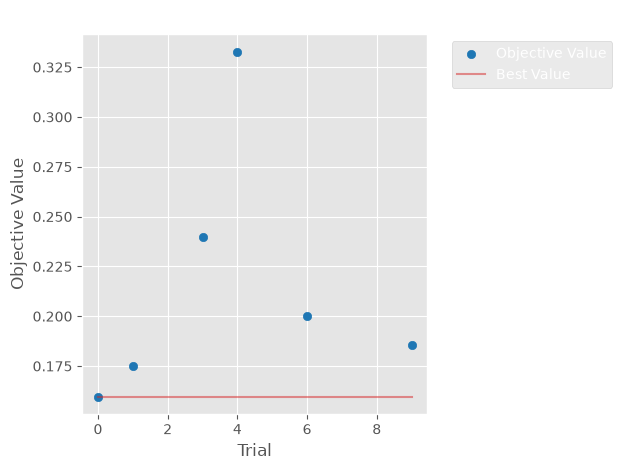

In [8]:
plt.style.use('dark_background')

fig = vis.plot_optimization_history(study)
plt.title("Lịch sử Tối ưu hóa (Optimization History)", fontsize=14)
plt.tight_layout()
plt.show()


/tmp/ipykernel_110412/1344079000.py:2: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  fig = vis.plot_param_importances(study)


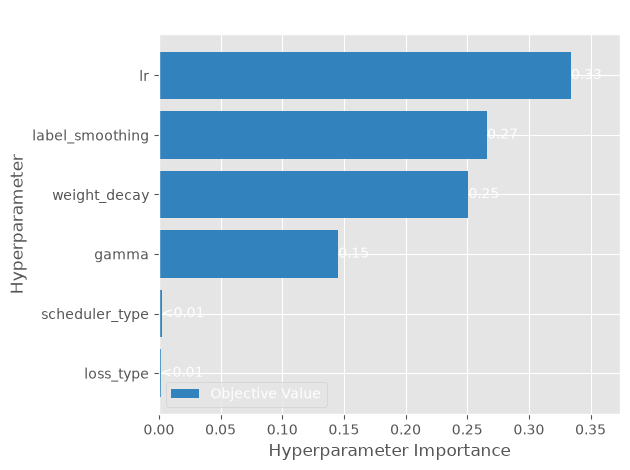

In [9]:
# 2. Mức độ quan trọng của các tham số (Parameter Importances)
fig = vis.plot_param_importances(study)
plt.title("Mức độ Quan trọng của Siêu tham số", fontsize=14)
plt.tight_layout()
plt.show()

### Kết luận

---

**Tham số tối ưu cuối cùng:**
- `learning_rate`: 0.000363
- `schedular`: cosin
- `loss`: Focal Loss
- `gamma`: 2.00
- `weight_decay`: 0.002